# Chapter 4 · The integral of non-negative functions: interactive demos

Companion to Chapter 4 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/04-integral.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatRangeSlider, Dropdown

from probnotes.integral import (EXAMPLES, SEQUENCES, combine, dyadic_integrals, periodic_fatou,
                                step_function, tail_infimum)
from probnotes.measurable import dyadic_approximation
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()


def broken(x, y):
    # NaNs at the jumps of a step function, so that no vertical segments are drawn
    jumps = np.flatnonzero(np.diff(y) != 0) + 1
    return np.insert(x, jumps, np.nan), np.insert(y.astype(float), jumps, np.nan)

## 1. The integral of a simple function, over $X$ and over $E$

For $f=\sum_i a_i\mathbf{1}_{A_i}\in\mathcal S^+(X)$ the integral is $\int_X f\,d\mu=\sum_i a_i\,\mu(A_i)$, with $0\cdot\infty=0$
(Definition 4.1), and $\int_E f\,d\mu=\int_X f\mathbf{1}_E\,d\mu=\sum_i a_i\,\mu(A_i\cap E)$. Here $f$ is written with
**overlapping** intervals, $f=2\cdot\mathbf{1}_{[0,2)}+1.5\cdot\mathbf{1}_{[1,3.5)}+1\cdot\mathbf{1}_{[3,5)}$; the code refines them into a partition,
and the integral computed from either representation is the same (Proposition 4.2 and Exercise 4.1). The gold region
is the integral over $E$.

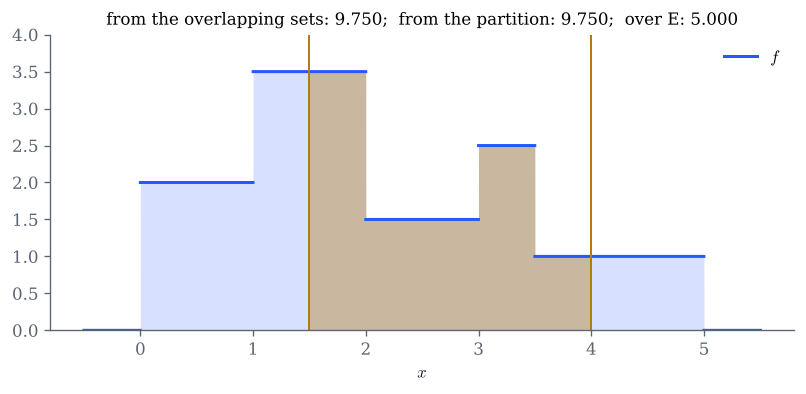

  value 1.0 on [(3.5, 5.0)]
  value 1.5 on [(2.0, 3.0)]
  value 2.0 on [(0.0, 1.0)]
  value 2.5 on [(3.0, 3.5)]
  value 3.5 on [(1.0, 2.0)]


In [2]:
COEFFS = [2.0, 1.5, 1.0]
SETS = [[(0, 2)], [(1, 3.5)], [(3, 5)]]
F = step_function(COEFFS, SETS)


def simple_demo(E=(1.5, 4.0)):
    x = np.linspace(-0.5, 5.5, 6001)
    y = F(x)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.fill_between(x, 0, y, step=None, color=COBALT, alpha=0.18, lw=0)
    inside = (x >= E[0]) & (x < E[1])
    ax.fill_between(x, 0, np.where(inside, y, 0.0), color=GOLD, alpha=0.4, lw=0)
    xs, ys = broken(x, y)
    ax.plot(xs, ys, color=COBALT, lw=1.8, label="$f$")
    for e in E:
        ax.axvline(e, color=GOLD, lw=1.2)
    direct = sum(a * sum(b - a_ for a_, b in S) for a, S in zip(COEFFS, SETS))
    ax.set(xlabel="$x$", ylim=(0, 4),
           title=(f"from the overlapping sets: {direct:.3f};  from the partition: {F.integral():.3f};  "
                  f"over E: {F.integral([E]):.3f}"))
    ax.grid(False)
    ax.legend(loc="upper right")
    plt.show()
    a, level_sets = F.canonical()
    for v, S in zip(a, level_sets):
        print(f"  value {v:.1f} on {[tuple(map(float, r)) for r in S]}")

simple_demo()

In [3]:
# Explore: move the set E = [a, b).
interact(simple_demo, E=FloatRangeSlider(value=(1.5, 4.0), min=-0.5, max=5.5, step=0.05,
                                         continuous_update=False, description="E"));

## 2. Monotone convergence: the areas under $f_n$ increase to the area under $f$

By the theorem of Beppo Levi (Theorem 4.8), $\int f\,dm=\lim_n\int f_n\,dm$ for the dyadic approximants
$f_n=\min(n,2^{-n}\lfloor 2^nf\rfloor)$ of Chapter 3. Since $f_n=2^{-n}\sum_{k=1}^{n2^n}\mathbf{1}_{\{f\ge k2^{-n}\}}$, the integral of $f_n$
only needs the measures $m(\{f\ge t\})$, so it is computed exactly. Left: $f$ and $f_n$. Centre: $\int f_k\,dm$ for
$k\le14$, increasing to $\int f\,dm$ (dashed). Right: the gap $\int f-\int f_k$; its rate depends on $f$ (Exercise 4.4).
For $1/x$ the integral is $+\infty$ and the integrals of $f_k$ grow like $1+\log k$.

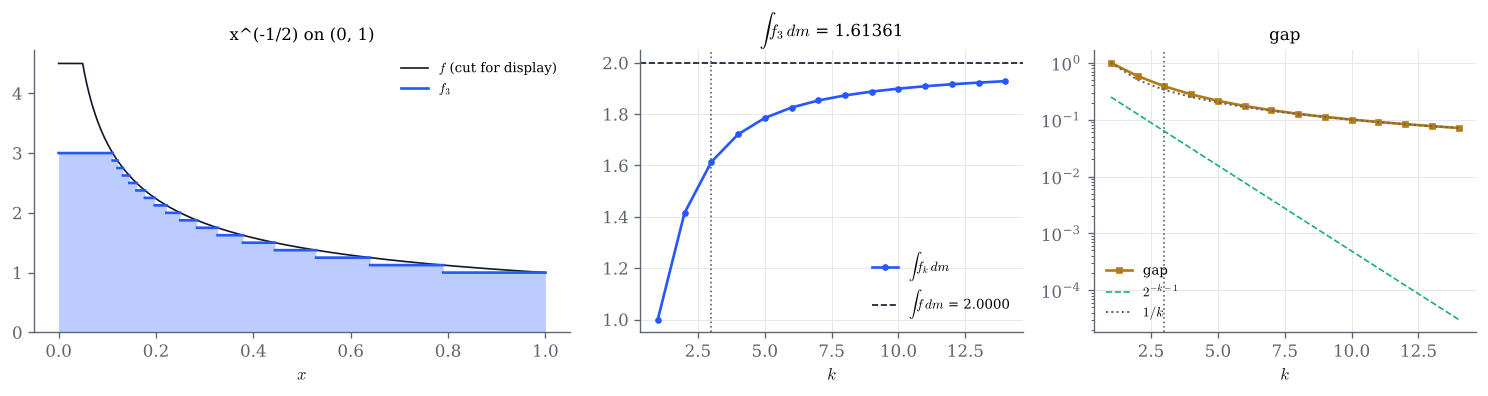

In [4]:
WINDOW = {"x on [0, 1]": (0, 1), "x^2 on [0, 1]": (0, 1), "x^(-1/2) on (0, 1)": (1e-6, 1),
          "-log x on (0, 1)": (1e-9, 1), "1/(1+x^2) on R": (-6, 6), "1/x on (0, 1)": (1e-6, 1)}
CACHE = {name: dyadic_integrals(ex.tail, 14) for name, ex in EXAMPLES.items()}


def monotone_demo(n=3, function="x^(-1/2) on (0, 1)"):
    ex = EXAMPLES[function]
    a, b = WINDOW[function]
    x = np.linspace(a, b, 20001)
    fx = ex.f(x)
    fn = dyadic_approximation(fx, n)
    fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(12.5, 3.4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
    ax.fill_between(x, 0, fn, color=COBALT, alpha=0.3, lw=0)
    ax.plot(x, np.minimum(fx, n + 1.5), color=INK, lw=1.0, label="$f$ (cut for display)")
    xs, ys = broken(x, fn)
    ax.plot(xs, ys, color=COBALT, lw=1.6, label=f"$f_{{{n}}}$")
    ax.set(xlabel="$x$", ylim=(0, min(fx.max(), n + 1.5) * 1.05), title=function)
    ax.grid(False)
    ax.legend(loc="upper right", fontsize=8)
    ks = np.arange(1, 15)
    I = CACHE[function]
    ax2.plot(ks, I, color=COBALT, marker="o", ms=3, label=r"$\int f_k\,dm$")
    if math.isfinite(ex.integral):
        ax2.axhline(ex.integral, color=INK, ls="--", lw=1, label=f"$\\int f\\,dm$ = {ex.integral:.4f}")
        ax3.plot(ks, ex.integral - I, color=GOLD, marker="s", ms=3, label="gap")
        ax3.plot(ks, 2.0 ** -(ks + 1.0), color=GREEN, ls="--", lw=1, label="$2^{-k-1}$")
        ax3.plot(ks, 1.0 / ks, color=GREY, ls=":", lw=1.2, label="$1/k$")
        ax3.set(yscale="log", xlabel="$k$", title="gap")
        ax3.axvline(n, color=GREY, ls=":", lw=1)
        ax3.legend(fontsize=8, loc="lower left")
    else:
        ax2.plot(ks, 1 + np.log(ks), color=GREEN, ls="--", lw=1, label="$1+\\log k$")
        ax3.axis("off")
        ax3.text(0.05, 0.5, "the integral of f is $+\\infty$:\nno gap to plot", fontsize=10)
    ax2.axvline(n, color=GREY, ls=":", lw=1)
    ax2.set(xlabel="$k$", title=f"$\\int f_{{{n}}}\\,dm$ = {I[n - 1]:.5f}")
    ax2.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    plt.show()

monotone_demo()

In [5]:
# Explore: move n and change the function. Which part of f does f_n miss: the top (cut at height n),
# the bottom (values below 2^-n), or a little everywhere (rounding)?
interact(monotone_demo,
         n=IntSlider(value=3, min=1, max=10, continuous_update=False, description="n"),
         function=Dropdown(options=list(EXAMPLES), value="x^(-1/2) on (0, 1)", description="f"));

## 3. Escaping mass and Fatou's lemma

For these sequences on $(\mathbb R,\mathcal B(\mathbb R),m)$, $f_n$ does not increase. Fatou's lemma (Lemma 4.16) says
$\int\liminf_n f_n\,dm\le\liminf_n\int f_n\,dm$, and its proof goes through $g_n=\inf_{k\ge n}f_k\nearrow\liminf_nf_n$.
Left: $f_n$ (blue), $f_{n+1}$ (gold) and $\inf_{n\le k\le K}f_k$ (green), computed exactly on the common refinement with
$K=n+60$. Right: $\int f_k\,dm$ and $\int\inf_{k\le j\le K}f_j\,dm$ for $k\le20$. The gap between the two curves is the
mass that escapes: it slides to infinity, concentrates on a shrinking set, or spreads out.

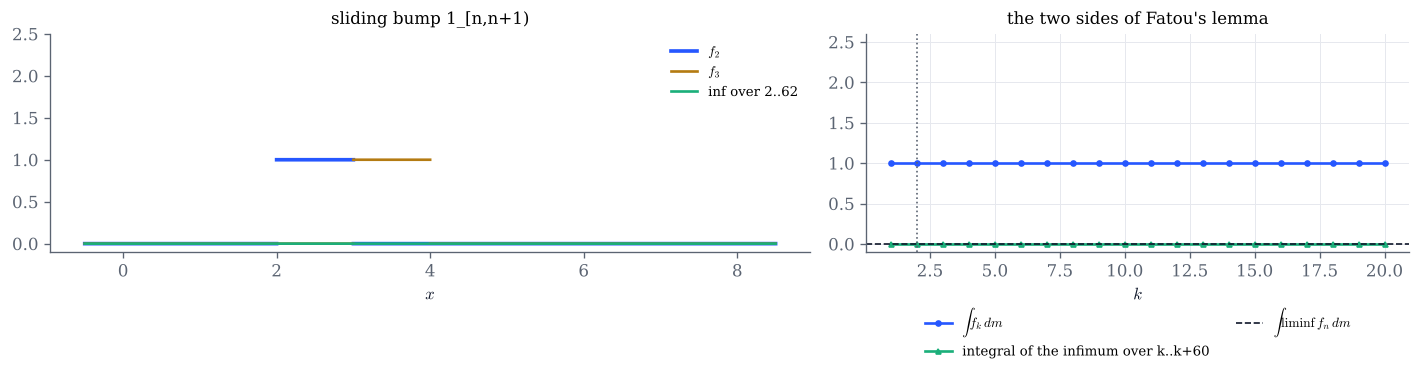

In [6]:
def fatou_demo(n=2, sequence="sliding bump 1_[n,n+1)"):
    seq, liminf = SEQUENCES[sequence]
    K = n + 60
    x = np.linspace(-0.5, 8.5, 18001)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
    for f, c, lab, lw in ((seq(n), COBALT, f"$f_{{{n}}}$", 2.2), (seq(n + 1), GOLD, f"$f_{{{n + 1}}}$", 1.6),
                          (tail_infimum(seq, n, K), GREEN, f"inf over {n}..{K}", 1.6)):
        xs, ys = broken(x, f(x))
        ax.plot(xs, ys, color=c, lw=lw, label=lab)
    ax.set(xlabel="$x$", ylim=(-0.1, max(2.5, seq(n)(x).max() * 1.1)), title=sequence)
    ax.grid(False)
    ax.legend(fontsize=8, loc="upper right")
    ks = np.arange(1, 21)
    ints = [seq(k).integral() for k in ks]
    infs = [tail_infimum(seq, k, k + 60).integral() for k in ks]
    ax2.plot(ks, ints, color=COBALT, marker="o", ms=3, label=r"$\int f_k\,dm$")
    ax2.plot(ks, infs, color=GREEN, marker="^", ms=3, label="integral of the infimum over k..k+60")
    ax2.axhline(liminf.integral(), color=INK, ls="--", lw=1, label=r"$\int\liminf f_n\,dm$")
    ax2.axvline(n, color=GREY, ls=":", lw=1)
    ax2.set(xlabel="$k$", ylim=(-0.1, 2.6), title="the two sides of Fatou's lemma")
    ax2.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    fig.tight_layout()
    plt.show()

fatou_demo()

In [7]:
# Explore: for which sequence are both sides of Fatou's lemma finite and different?
interact(fatou_demo,
         n=IntSlider(value=2, min=1, max=7, continuous_update=False, description="n"),
         sequence=Dropdown(options=list(SEQUENCES), value="sliding bump 1_[n,n+1)", description="sequence"));

## 4. Fatou's lemma on a finite space

On $X=\{0,\dots,N-1\}$ with weights $w_x>0$, a periodic sequence $f_n=h_{n \bmod p}$ has $\liminf_nf_n=\min_jh_j$ and
$\liminf_n\int f_n=\min_j\int h_j$, so both sides of Fatou's lemma are exact. Equality holds if and only if one $h_j$ is the
smallest at every point (Exercise 4.9). The bars are the values $h_j(x)$; the black line is $\min_jh_j$.

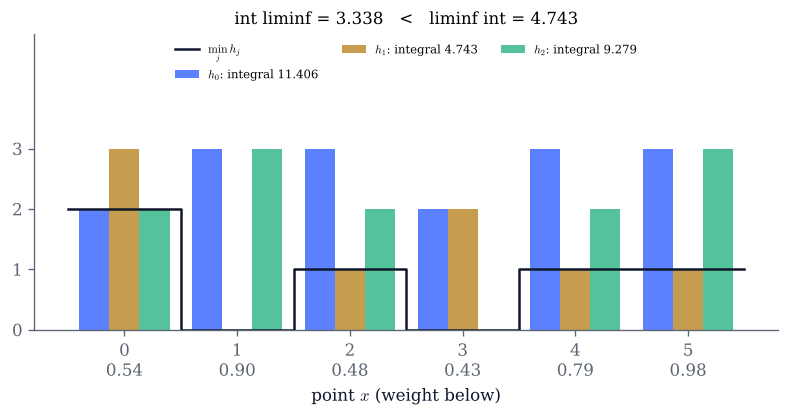

In [8]:
def finite_fatou_demo(seed=4, p=3, N=6):
    rng = np.random.default_rng(seed)
    h = rng.integers(0, 4, size=(p, N)).astype(float)
    w = rng.random(N)
    lhs, rhs = periodic_fatou(h, w)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    colors = [COBALT, GOLD, GREEN, "#6250D6", "#E34948"]
    width = 0.8 / p
    for j in range(p):
        ax.bar(np.arange(N) + (j - (p - 1) / 2) * width, h[j], width=width, color=colors[j % 5], alpha=0.75,
               label=f"$h_{j}$: integral {np.dot(h[j], w):.3f}")
    ax.step(np.arange(N + 1) - 0.5, np.append(h.min(axis=0), h.min(axis=0)[-1]), where="post", color=INK, lw=1.5,
            label="$\\min_j h_j$")
    ax.set(xlabel="point $x$ (weight below)", xticks=range(N),
           xticklabels=[f"{x}\n{w[x]:.2f}" for x in range(N)], ylim=(0, 4.9), yticks=[0, 1, 2, 3],
           title=f"int liminf = {lhs:.3f}   {'<' if lhs < rhs - 1e-12 else '='}   liminf int = {rhs:.3f}")
    ax.grid(False)
    ax.legend(fontsize=7, loc="upper center", ncol=3)
    plt.show()

finite_fatou_demo()

In [9]:
interact(finite_fatou_demo,
         seed=IntSlider(value=4, min=0, max=200, continuous_update=False, description="seed"),
         p=IntSlider(value=3, min=1, max=5, continuous_update=False, description="period p"),
         N=IntSlider(value=6, min=1, max=10, continuous_update=False, description="N"));

## Things to try

- In section 1, move $E$ so that $\int_Ef\,dm$ is exactly half of $\int_Xf\,dm$. Is there only one such $E=[a,b)$ with $a=0$?
- In section 2, compare $x^2$ and $x^{-1/2}$: why does the gap halve at each step for one and decrease like $1/n$ for the other?
  Where on the left plot is the missing area?
- In section 2, for $1/(1+x^2)$ on $\mathbb R$, most of the gap comes from the region where $f<2^{-n}$. How wide is it?
- In section 3, the spike and the spreading plateau give $\int\inf_{k\le j\le K}f_j=k/K$, not $0$. Why does a finite $K$ not see
  the true infimum, and why does it not matter as $K\to\infty$?
- In section 4, set $p=1$. Why is Fatou's lemma then always an equality? Find a seed with $p=3$ where it is an equality.